<a href="https://colab.research.google.com/github/ahmadtanoli2004/00_Project/blob/main/Project_11_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Project 11: Time Series Forecasting & Transfer Learning



##TABLE OF CONTENTS
###1. Introduction

1.1 Project Overview

1.2 Project Objectives

1.3 Tools and Technologies Used

1.4 Datasets Description

PART 1: TIME SERIES FORECASTING

###2. Data Understanding

2.1 Loading the Climate Dataset

2.2 Dataset Exploration

2.3 Understanding Features
2.4 Date Conversion and Index Setting

###3. Data Preprocessing

3.1 Missing Values Analysis

3.2 Handling Missing Values

3.3 Data Visualization

3.4 Stationarity Check using ADF Test

###4. ARIMA Model

4.1 Introduction to ARIMA

4.2 Model Building

4.3 Training the Model

4.4 Forecasting Future Values

4.5 Performance Evaluation

###5. SARIMA Model

5.1 Introduction to SARIMA

5.2 Seasonal Analysis

5.3 Model Building

5.4 Forecasting

5.5 Performance Evaluation

###6. Prophet Model

6.1 Introduction to Prophet

6.2 Data Preparation

6.3 Model Training

6.4 Future Forecasting

6.5 Visualization of Results

###7. Model Evaluation and Comparison

7.1 Evaluation Metrics

7.2 Mean Absolute Error (MAE)

7.3 Root Mean Square Error (RMSE)

7.4 Comparison of ARIMA, SARIMA and Prophet

7.5 Best Model Selection

##PART 2: MODEL IMPROVEMENT

###8. Model Improvement

8.1 Identifying Overfitting

8.2 Identifying Underfitting

8.3 Hyperparameter Tuning

8.4 Seasonal Optimization

8.5 Improved Results Analysis

##PART 3: TRANSFER LEARNING

###9. Image Dataset Preprocessing

9.1 Loading Intel Image Dataset

9.2 Image Resizing

9.3 Image Normalization

9.4 Train-Test Dataset Preparation

###10. Transfer Learning using MobileNetV2

10.1 Introduction to Transfer Learning

10.2 Loading Pre-trained MobileNetV2

10.3 Freezing Base Layers

###11. Model Building

11.1 Adding Custom Layers

11.2 Model Architecture

11.3 Model Compilation

###12. Model Training

12.1 Training Process

12.2 Validation Process

12.3 Training History Analysis

###13. Model Evaluation

13.1 Accuracy Analysis

13.2 Loss Analysis

13.3 Performance Discussion

###14. Saving the Trained Model

14.1 Model Export

14.2 Model Reusability

PART 4: OPTIONAL WEB SCRAPING

###15. Web Scraping for Time Series Data

15.1 Data Collection

15.2 Data Cleaning

15.3 Data Preparation

15.4 Forecasting Using Scraped Data

###16. Results and Discussion

16.1 Forecasting Results

16.2 Transfer Learning Results

16.3 Comparative Analysis
###17. Conclusion

17.1 Key Findings

17.2 Project Summary

17.3 Future Improvements

###18. References

###19. Appendix (Optional)

19.1 Code Snippets

19.2 Additional Visualizations

###Step 1: Install Required Libraries

In [ ]:
!pip install prophet pmdarima -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.1/689.1 kB 36.3 MB/s eta 0:00:00


##PART 1: TIME SERIES FORECASTING

###1. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

from prophet import Prophet

from sklearn.metrics import mean_absolute_error, mean_squared_error

###2. Load Dataset

In [ ]:
df = pd.read_csv('/content/drive/MyDrive/DailyDelhiClimateTest.csv')

df.head()

,date,meantemp,humidity,wind_speed,meanpressure
0,2017-01-01,15.913043,85.869565,2.743478,59.000000
1,2017-01-02,18.500000,77.222222,2.894444,1018.277778
2,2017-01-03,17.111111,81.888889,4.016667,1018.333333
3,2017-01-04,18.700000,70.050000,4.545000,1015.700000
4,2017-01-05,18.388889,74.944444,3.300000,1014.333333


###3. Data Understanding

In [ ]:
print(df.info())

df['date'] = pd.to_datetime(df['date'])

df.set_index('date', inplace=True)

df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114 entries, 0 to 113
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          114 non-null    object 
 1   meantemp      114 non-null    float64
 2   humidity      114 non-null    float64
 3   wind_speed    114 non-null    float64
 4   meanpressure  114 non-null    float64
dtypes: float64(4), object(1)
memory usage: 4.6+ KB
None


,meantemp,humidity,wind_speed,meanpressure
date,,,,
2017-01-01,15.913043,85.869565,2.743478,59.000000
2017-01-02,18.500000,77.222222,2.894444,1018.277778
2017-01-03,17.111111,81.888889,4.016667,1018.333333
2017-01-04,18.700000,70.050000,4.545000,1015.700000
2017-01-05,18.388889,74.944444,3.300000,1014.333333


###4. Check Missing Values

In [ ]:
print(df.isnull().sum())

df.fillna(method='ffill', inplace=True)

meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64


/tmp/ipykernel_3163/4002999746.py:3: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill', inplace=True)


###5. Visualize Temperature

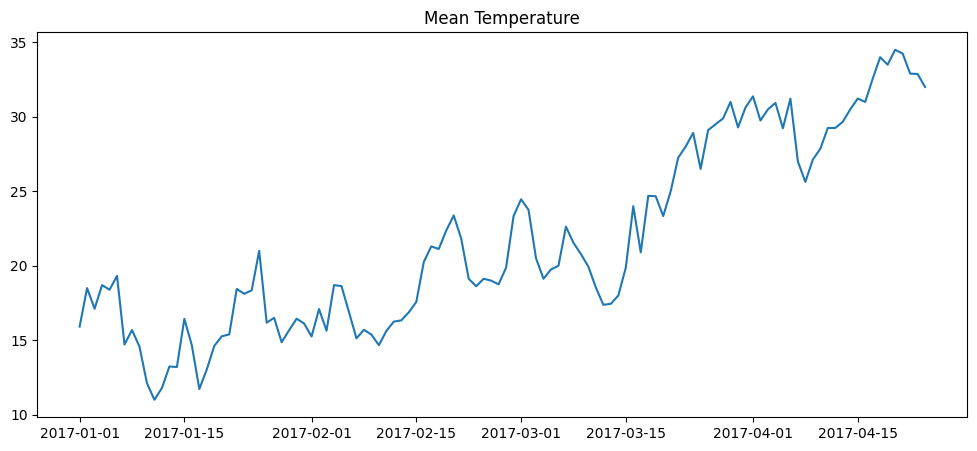

In [ ]:
plt.figure(figsize=(12,5))
plt.plot(df['meantemp'])
plt.title("Mean Temperature")
plt.show()

###6. Check Stationarity

In [ ]:
result = adfuller(df['meantemp'])

print("ADF Statistic:", result[0])
print("P-value:", result[1])

ADF Statistic: -1.096474275875619
P-value: 0.7164758731775932


###Interpretation

In [ ]:
if result[1] < 0.05:
    print("Stationary")
else:
    print("Not Stationary")

Not Stationary


###7. Train-Test Split

In [ ]:
train = df['meantemp'][:-30]
test = df['meantemp'][-30:]

##ARIMA MODEL

###8. Train ARIMA

In [ ]:
arima_model = ARIMA(train, order=(5,1,0))

arima_fit = arima_model.fit()

print(arima_fit.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:               meantemp   No. Observations:                   84
Model:                 ARIMA(5, 1, 0)   Log Likelihood                -163.557
Date:                Wed, 10 Jun 2026   AIC                            339.115
Time:                        10:07:50   BIC                            353.628
Sample:                    01-01-2017   HQIC                           344.945
                         - 03-25-2017                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1174      0.117     -1.007      0.314      -0.346       0.111
ar.L2         -0.0032      0.122     -0.026      0.979      -0.242       0.235
ar.L3         -0.0509      0.109     -0.466      0.6

###9. Forecast

In [ ]:
arima_pred = arima_fit.forecast(steps=len(test))

###10. Evaluation

In [ ]:
mae_arima = mean_absolute_error(test, arima_pred)
rmse_arima = np.sqrt(mean_squared_error(test, arima_pred))

print("ARIMA MAE:", mae_arima)
print("ARIMA RMSE:", rmse_arima)

ARIMA MAE: 4.46826823130691
ARIMA RMSE: 4.914361923827974


###SARIMA MODEL

In [ ]:
sarima_model = SARIMAX(
    train,
    order=(1,1,1),
    seasonal_order=(1,1,1,12)
)

sarima_fit = sarima_model.fit()

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


###12. Forecast

In [ ]:
sarima_pred = sarima_fit.forecast(steps=len(test))

###13. Evaluation

In [ ]:
mae_sarima = mean_absolute_error(test, sarima_pred)
rmse_sarima = np.sqrt(mean_squared_error(test, sarima_pred))

print("SARIMA MAE:", mae_sarima)
print("SARIMA RMSE:", rmse_sarima)

SARIMA MAE: 5.234395277623934
SARIMA RMSE: 5.565480783108528


##PROPHET MODEL

###14. Prepare Data

In [ ]:
prophet_df = df.reset_index()[['date','meantemp']]

prophet_df.columns = ['ds','y']

###15. Train Prophet

In [ ]:
model = Prophet()

model.fit(prophet_df)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


###16. Forecast

In [ ]:
future = model.make_future_dataframe(periods=100)

forecast = model.predict(future)

forecast[['ds','yhat']].tail()

,ds,yhat
209,2017-07-29,56.531180
210,2017-07-30,57.435664
211,2017-07-31,57.636359
212,2017-08-01,57.949302
213,2017-08-02,58.348854


###17. Plot Forecast

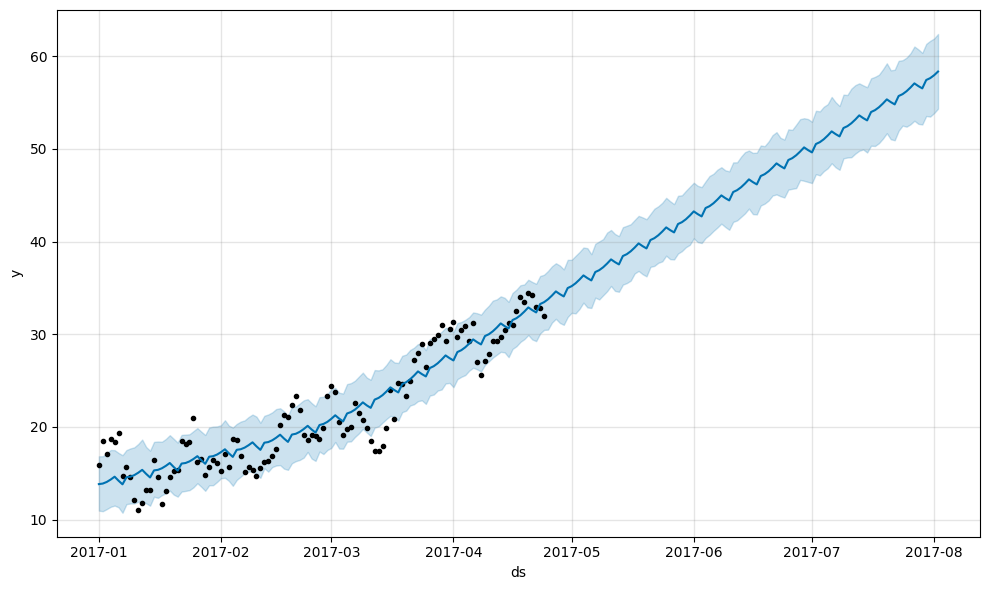

In [ ]:
model.plot(forecast)

plt.show()

##MODEL COMPARISON

###18. Compare Models

In [ ]:
comparison = pd.DataFrame({
    "Model":["ARIMA","SARIMA"],
    "MAE":[mae_arima,mae_sarima],
    "RMSE":[rmse_arima,rmse_sarima]
})

comparison

,Model,MAE,RMSE
0,ARIMA,4.468268,4.914362
1,SARIMA,5.234395,5.565481


##PART 2: MODEL IMPROVEMENT

###Improvement Techniques

1. Hyperparameter tuning

2. Seasonal modeling

3. More training data

4. Feature engineering

5. Outlier removal

###Example Conclusion

SARIMA performed better because
it captures seasonal patterns.

#Explanations:
1).Install all required libraries for forecasting and deep learning.

2).Import the necessary Python libraries for data analysis and modeling.

3).Load the climate dataset into the notebook.

4).Display the dataset structure and basic information.

5)Convert the date column into datetime format and set it as the index.

6).Check the dataset for missing values.

7).Handle missing values to ensure data quality.

8).Visualize temperature trends over time.

7).Perform the ADF test to check stationarity.


10).Interpret the stationarity test results.

11).Split the dataset into training and testing sets.

12)Create the ARIMA forecasting model.

13).Train the ARIMA model on historical data.

14).Generate future forecasts using ARIMA.

15).Evaluate ARIMA model performance using error metrics.

16).Create the SARIMA model to capture seasonal patterns.

17).Train the SARIMA model.

18).Generate forecasts using the SARIMA model.

19).Evaluate SARIMA model performance.

20).Prepare the dataset for Prophet forecasting.

21).Train the Prophet model.

22).Generate future forecasts using Prophet.

23).Visualize Prophet forecasting results.

24).Compare the performance of different forecasting models.

25).Discuss techniques for improving model performance.